# Chapter 6 — 분류를 위한 미세 조정(Fine-tuning) : 코드 해설 노트북 (Python 초보용)

> `Chapter_6_Excercise_Finetuning_Classification.ipynb` 의 원본 코드 셀은 그대로 두고, 번호가 붙은 셀마다 바로 위에 설명을 넣은 해설판입니다. 이 노트북은 셀이 2개뿐이지만 각 셀이 길어서, 설명을 **함수 단위 / 단계 단위**로 나누었습니다.

## 이 챕터에서 하는 일 (한 문장)

이미 글을 잘 아는 GPT-2 를 가져와, **문자 메시지가 스팸인지 아닌지 가려내는 분류기**로 고쳐 씁니다.

## 미세 조정(fine-tuning)이란?

| | 사전 학습 (Chapter 5) | 미세 조정 (이 챕터) |
|---|---|---|
| 출발점 | 무작위 가중치 | **이미 학습된** 가중치 |
| 데이터 | 엄청난 양의 일반 글 | 적은 양의 **목적에 맞는** 데이터 |
| 목표 | 언어 전반을 익힘 | 특정 작업(스팸 분류)을 잘하게 함 |
| 비유 | 초·중·고 12년 교육 | 입사 후 2주 직무 교육 |

Chapter 5 에서 보았듯 처음부터 학습하려면 데이터와 시간이 많이 듭니다. 그래서 **잘 학습된 모델을 가져와 끝부분만 살짝 고치는** 방법을 씁니다.

## 모델에서 무엇을 바꾸나

```
 before :  ... -> final_norm -> out_head (768 -> 50257)   "which token comes next?"
 after  :  ... -> final_norm -> out_head (768 -> 2)       "ham(0) or spam(1)?"
```
출력 헤드만 **5만여 개 → 2개**로 갈아 끼웁니다. 그리고 문장의 **마지막 토큰** 자리에서 나온 점수 2개로 판정합니다.

## 용어

| 낱말 | 뜻 |
|---|---|
| **spam** | 광고·사기성 스팸 메시지 (라벨 1) |
| **ham** | 정상 메시지 (라벨 0). 스팸의 반대말로 쓰는 관용 표현 |
| **패딩(padding)** | 길이가 다른 문장들을 같은 길이로 맞추려고 뒤에 채우는 빈칸 토큰 |
| **동결(freeze)** | 가중치가 학습으로 바뀌지 않게 잠그는 것 |
| **정확도(accuracy)** | 맞힌 개수 ÷ 전체 개수 |

## 셀 구성

| 셀 | 내용 |
|---|---|
| 1 | 필요한 **함수와 클래스 정의** (데이터 준비 4개 + 평가·학습 6개) |
| 2 | **실행** : 데이터 준비 → 모델 불러오기 → 헤드 교체·동결 → 학습 → 그래프 (6단계) |

---
## 셀 1 — 함수와 클래스 정의

### 🎯 이 셀이 하는 일
실제 실행(셀 2)에 필요한 도구들을 모두 **정의만** 해 둡니다. 실행해도 출력은 없습니다.

| 구분 | 이름 | 한 줄 역할 |
|---|---|---|
| 데이터 | `download_and_unzip_spam_data` | 스팸 데이터 내려받고 압축 풀기 |
| 데이터 | `create_balanced_dataset` | 스팸과 정상 메시지 개수를 같게 맞추기 |
| 데이터 | `random_split` | 학습/검증/테스트용으로 나누기 |
| 데이터 | `SpamDataset` | 글 → 토큰 ID + 길이 맞추기(패딩) |
| 평가 | `calc_accuracy_loader` | 정확도 계산 |
| 평가 | `calc_loss_batch` | 배치 하나의 손실 |
| 평가 | `calc_loss_loader` | 로더 전체의 평균 손실 |
| 평가 | `evaluate_model` | 학습/검증 손실 중간 점검 |
| 학습 | `train_classifier_simple` | 학습 루프 |
| 그림 | `plot_values` | 손실/정확도 그래프 저장 |

### 새로 등장하는 import

| 코드 | 용도 |
|---|---|
| `import zipfile` | zip 압축 풀기 |
| `from pathlib import Path` | 파일 경로를 편하게 다루는 도구 |
| `import time` | 걸린 시간 재기 |
| `import pandas as pd` | **표(엑셀 같은) 데이터**를 다루는 라이브러리. 관례적으로 `pd` 라고 부름 |
| `from previous_chapters import GPTModel, load_gpt2_model` | Chapter 4 의 모델과, 학습된 GPT-2 가중치를 불러오는 함수 |

---
### ① `download_and_unzip_spam_data`

```python
if data_file_path.exists():
    print(f"{data_file_path} already exists. Skipping download and extraction.")
    return
```
이미 파일이 있으면 아무것도 하지 않고 끝냅니다. 값 없이 `return` 만 쓰면 **함수를 즉시 종료**합니다.

```python
response = requests.get(url, stream=True, timeout=60)
response.raise_for_status()
with open(zip_path, "wb") as out_file:
    for chunk in response.iter_content(chunk_size=8192):
        if chunk:
            out_file.write(chunk)
```
`stream=True` 와 `iter_content(chunk_size=8192)` 는 파일을 한꺼번에 받지 않고 **8192바이트씩 조금씩** 받아 쓰는 방식입니다. 큰 파일도 메모리를 적게 쓰며 받을 수 있습니다.

```python
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extracted_path)

original_file_path = Path(extracted_path) / "SMSSpamCollection"
os.rename(original_file_path, data_file_path)
```
- `extractall` : 압축을 풉니다.
- `Path(폴더) / "파일이름"` : `Path` 객체에서는 **`/` 가 "경로 이어 붙이기"** 입니다(나눗셈이 아닙니다).
- `os.rename` : 파일 이름에 `.tsv` 확장자를 붙여 줍니다. (tsv = 탭으로 구분된 표 파일)

---
### ② `create_balanced_dataset` — 개수 맞추기

원본 데이터는 정상(ham) 메시지가 약 4,800개, 스팸이 약 750개로 **심하게 치우쳐** 있습니다. 이대로 학습하면 모델이 "무조건 정상이라고 답하기"만 해도 정확도가 87% 가 나와 버립니다. 그래서 개수를 똑같이 맞춥니다.

```python
num_spam = df[df["Label"] == "spam"].shape[0]
ham_subset = df[df["Label"] == "ham"].sample(num_spam, random_state=123)
balanced_df = pd.concat([ham_subset, df[df["Label"] == "spam"]])
```

| 코드 | 설명 |
|---|---|
| `df` | DataFrame, 즉 **표**. 행 = 메시지 하나, 열 = `Label`, `Text` |
| `df["Label"] == "spam"` | 각 행이 스팸인지 True/False 로 표시한 목록 |
| `df[ 그 목록 ]` | True 인 행만 골라낸 표 (**조건 필터링**) |
| `.shape[0]` | 행의 개수 (`shape` 는 [행 수, 열 수]) |
| `.sample(n, random_state=123)` | 무작위로 n개 행을 뽑음. `random_state` 는 시드 |
| `pd.concat([a, b])` | 두 표를 위아래로 이어 붙임 |

많은 쪽(ham)을 적은 쪽(spam) 개수에 맞춰 줄이는 이 방법을 **언더샘플링**이라고 합니다.

---
### ③ `random_split` — 세 묶음으로 나누기

```python
df = df.sample(frac=1, random_state=123).reset_index(drop=True)
train_end = int(len(df) * train_frac)
validation_end = train_end + int(len(df) * validation_frac)

train_df = df[:train_end]
validation_df = df[train_end:validation_end]
test_df = df[validation_end:]
```
- `sample(frac=1)` : 전체의 100% 를 무작위로 뽑음 = **행 순서를 섞는다**는 뜻입니다.
- `reset_index(drop=True)` : 섞인 뒤 행 번호를 0부터 다시 매깁니다.
- 그다음은 리스트 슬라이싱과 같습니다.

```
 |<------- train 70% ------->|<- val 10% ->|<--- test 20% --->|
 0                       train_end   validation_end          end
```

| 묶음 | 용도 | 비유 |
|---|---|---|
| 학습(train) | 가중치를 고치는 데 사용 | 교과서 문제 |
| 검증(validation) | 학습 도중 실력 점검 | 모의고사 |
| 테스트(test) | 다 끝난 뒤 최종 평가 | 수능 |

---
### ④ `SpamDataset` 클래스

**`__init__`**
```python
self.data = pd.read_csv(csv_file)
self.encoded_texts = [tokenizer.encode(text) for text in self.data["Text"]]
```
CSV 를 표로 읽고, `Text` 열의 모든 메시지를 토큰 ID 리스트로 바꿉니다(리스트 컴프리헨션).

```python
if max_length is None:
    self.max_length = self._longest_encoded_length()
else:
    self.max_length = max_length
    self.encoded_texts = [encoded_text[:self.max_length]
                          for encoded_text in self.encoded_texts]
```
- 길이를 지정하지 않으면(`None`) **가장 긴 메시지의 길이**를 기준으로 삼습니다.
- 지정하면 그보다 긴 메시지는 **잘라냅니다**(`[:max_length]`, truncation).
- `is None` : "값이 없음"인지 확인할 때는 `==` 대신 `is` 를 쓰는 것이 관례입니다.

```python
self.encoded_texts = [
    encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
    for encoded_text in self.encoded_texts
]
```
**패딩** : 짧은 메시지 뒤에 50256 번 토큰을 채워 모든 메시지 길이를 똑같이 만듭니다.
- `[50256] * 3` → `[50256, 50256, 50256]` (리스트에 숫자를 곱하면 반복)
- 리스트 `+` 리스트 → 이어 붙이기

```
 max_length = 6
 [101, 55, 9]           ->  [101, 55, 9, 50256, 50256, 50256]
 [7, 8, 9, 10, 11, 12]  ->  [7, 8, 9, 10, 11, 12]
```
**왜 길이를 맞출까?** 배치는 `[배치 크기, 길이]` 의 **직사각형 표**여야 하기 때문입니다. 길이가 제각각이면 한 텐서로 묶을 수 없습니다.

**`__getitem__`**
```python
encoded = self.encoded_texts[index]
label = self.data.iloc[index]["Label"]
return (torch.tensor(encoded, dtype=torch.long),
        torch.tensor(label, dtype=torch.long))
```
- `.iloc[index]` : 표에서 **index 번째 행**을 꺼냅니다. 거기서 `["Label"]` 열 값(0 또는 1)을 읽습니다.
- `dtype=torch.long` : 정수형 텐서로 만듭니다. 토큰 ID 와 라벨은 정수여야 합니다.
- Chapter 2 의 데이터셋은 (입력 토큰들, **정답 토큰들**)을 돌려줬지만, 여기서는 (입력 토큰들, **정답 라벨 1개**)를 돌려줍니다.

**`_longest_encoded_length`**
```python
max_length = 0
for encoded_text in self.encoded_texts:
    encoded_length = len(encoded_text)
    if encoded_length > max_length:
        max_length = encoded_length
return max_length
```
"지금까지 본 것 중 최댓값"을 갱신해 가며 가장 긴 길이를 찾는 전형적인 방법입니다. 이름 앞의 밑줄 `_` 은 "클래스 **내부에서만** 쓰는 보조 메서드"라는 관례적 표시입니다.

---
### ⑤ `calc_accuracy_loader` — 정확도

```python
model.eval()
correct_predictions, num_examples = 0, 0
...
for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
        input_batch, target_batch = input_batch.to(device), target_batch.to(device)
        with torch.no_grad():
            logits = model(input_batch)[:, -1, :]
        predicted_labels = torch.argmax(logits, dim=-1)
        num_examples += predicted_labels.shape[0]
        correct_predictions += (predicted_labels == target_batch).sum().item()
    else:
        break
return correct_predictions / num_examples
```

| 코드 | 설명 |
|---|---|
| `model(input_batch)[:, -1, :]` | 모델 출력 `[b, T, 2]` 에서 **마지막 토큰 자리만** → `[b, 2]` |
| `torch.argmax(logits, dim=-1)` | 두 점수 중 큰 쪽의 번호 → 0(정상) 또는 1(스팸) |
| `predicted_labels == target_batch` | 예측과 정답이 같은지 True/False |
| `.sum()` | True 의 개수 (True 는 1, False 는 0 으로 셈) |
| `.item()` | 텐서 → 파이썬 숫자 |
| `correct_predictions / num_examples` | 맞힌 수 ÷ 전체 수 = 정확도 |

**⭐ 왜 마지막 토큰일까?** GPT 는 causal mask 때문에 각 토큰이 **자기 앞쪽만** 볼 수 있습니다. 따라서 **문장 전체를 다 본 토큰은 맨 마지막 토큰 하나뿐**입니다. 문장 전체에 대한 판정은 그 자리에서 내리는 것이 가장 합리적입니다.

```
 tokens :  t0   t1   t2   ...   t_last
 sees   :  t0   t0~1 t0~2 ...   everything   <- use this one
```

---
### ⑥ `calc_loss_batch`
```python
logits = model(input_batch)[:, -1, :]
loss = torch.nn.functional.cross_entropy(logits, target_batch)
```
Chapter 5 와 비교하면 훨씬 단순합니다. 마지막 자리만 쓰므로 로짓이 이미 `[b, 2]`, 정답이 `[b]` 모양이라 **`flatten` 이 필요 없습니다.** "문제 b개, 보기 2개"인 크로스 엔트로피입니다.

### ⑦ `calc_loss_loader`, ⑧ `evaluate_model`
Chapter 5 와 **완전히 같은** 코드입니다. (평균 손실 계산 / `eval()` → `no_grad()` → `train()` 샌드위치)

---
### ⑨ `train_classifier_simple` — 학습 루프

```python
for epoch in range(num_epochs):
    model.train()
    for input_batch, target_batch in train_loader:
        optimizer.zero_grad()
        loss = calc_loss_batch(input_batch, target_batch, model, device)
        loss.backward()
        optimizer.step()
        examples_seen += input_batch.shape[0]
        global_step += 1
        if global_step % eval_freq == 0:
            ...  # 손실 점검 및 출력
    train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=eval_iter)
    val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=eval_iter)
    print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
    print(f"Validation accuracy: {val_accuracy*100:.2f}%")
```
뼈대(`zero_grad → loss → backward → step`)는 Chapter 5 와 똑같습니다. 달라진 점만 보면 됩니다.

| | Chapter 5 | Chapter 6 |
|---|---|---|
| 세는 단위 | `tokens_seen` (본 토큰 수) | `examples_seen` (본 메시지 수) |
| 에포크 끝에 하는 일 | 샘플 문장 생성 | **정확도** 계산·출력 |
| 돌려주는 것 | 손실 기록 | 손실 기록 + **정확도 기록** |

- `input_batch.shape[0]` : 배치 안의 메시지 개수
- `print(..., end="")` : 출력 뒤에 **줄을 바꾸지 않아** 다음 `print` 가 같은 줄에 이어집니다.
- `{값*100:.2f}%` : 0.975 → `97.50%`

---
### ⑩ `plot_values` — 그래프 저장
Chapter 5 의 `plot_losses` 와 같은 구조입니다(아래 x축 = 에포크, 위 x축 = 본 메시지 수). `label="loss"` 또는 `"accuracy"` 를 받아 축 이름과 **파일 이름**(`output/loss-plot.pdf`, `output/accuracy-plot.pdf`)에 씁니다. `label.capitalize()` 는 첫 글자를 대문자로 바꿉니다(`loss` → `Loss`).

In [1]:
# 1
# Copyright (c) Sebastian Raschka under Apache License 2.0 (see LICENSE.txt).
# Source for "Build a Large Language Model From Scratch"
#   - https://www.manning.com/books/build-a-large-language-model-from-scratch
# Code: https://github.com/rasbt/LLMs-from-scratch

# 6장의 주요 내용을 요약한 파일: 분류(Classification)를 위한 GPT 미세 조정
import requests
import zipfile
import os
from pathlib import Path
import time

import matplotlib.pyplot as plt
import pandas as pd
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader

# 이전 챕터나 별도 모듈에서 정의된 GPT 모델 관련 함수들 임포트
from previous_chapters import GPTModel, load_gpt2_model

# -----------------------------------------------------------------------------
# 1. 데이터 준비 유틸리티 함수들
# -----------------------------------------------------------------------------

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
    """
    스팸 데이터셋(SMS Spam Collection)을 다운로드하고 압축을 해제하는 함수
    """
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return

    # 파일 다운로드 (스트리밍 방식)
    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()
    with open(zip_path, "wb") as out_file:
        for chunk in response.iter_content(chunk_size=8192):
            if chunk:
                out_file.write(chunk)

    # 압축 해제
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extracted_path)

    # 압축 해제된 파일에 .tsv 확장자 추가 (Pandas로 읽기 편하게)
    original_file_path = Path(extracted_path) / "SMSSpamCollection"
    os.rename(original_file_path, data_file_path)
    print(f"File downloaded and saved as {data_file_path}")


def create_balanced_dataset(df):
    """
    데이터 불균형 해결을 위한 함수.
    스팸(spam) 데이터 수에 맞춰 햄(ham, 정상 메일) 데이터를 언더샘플링합니다.
    """
    # "spam" 라벨의 개수 계산
    num_spam = df[df["Label"] == "spam"].shape[0]  # df의 shape: [행 개수, 열 개수] [0]:행 갯수임

    # "ham" 데이터 중에서 "spam" 개수만큼만 무작위 추출
    ham_subset = df[df["Label"] == "ham"].sample(num_spam, random_state=123)

    # 두 데이터셋 병합
    balanced_df = pd.concat([ham_subset, df[df["Label"] == "spam"]])

    return balanced_df


def random_split(df, train_frac, validation_frac):
    """
    데이터셋을 학습(Train), 검증(Validation), 테스트(Test) 셋으로 분할하는 함수
    """
    # 전체 데이터 섞기
    df = df.sample(frac=1, random_state=123).reset_index(drop=True)

    # 분할 지점(인덱스) 계산
    train_end = int(len(df) * train_frac)
    validation_end = train_end + int(len(df) * validation_frac)

    # 데이터 분할
    train_df = df[:train_end]
    validation_df = df[train_end:validation_end]
    test_df = df[validation_end:]

    return train_df, validation_df, test_df


class SpamDataset(Dataset):
    """
    PyTorch Dataset 클래스 정의.
    텍스트를 토큰화하고, 패딩(Padding) 처리를 수행합니다.
    """
    def __init__(self, csv_file, tokenizer, max_length=None, pad_token_id=50256):
        self.data = pd.read_csv(csv_file)

        # 1. 텍스트 데이터를 토큰 ID 리스트로 변환 (Tokenization)
        self.encoded_texts = [
            tokenizer.encode(text) for text in self.data["Text"]
        ]

        # 2. 최대 길이(max_length) 설정
        if max_length is None:
            self.max_length = self._longest_encoded_length()
        else:
            self.max_length = max_length
            # max_length보다 긴 문장은 잘라냄 (Truncation)
            # TODO: 시퀀스를 최대 길이로 잘라낼 끝 인덱스를 채우세요.
            # 힌트: 설정된 최대 길이 `self.max_length`로 슬라이싱하면 됩니다.
            self.encoded_texts = [
                # encoded_text[:????]
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]

        # 3. 패딩(Padding): 모든 시퀀스 길이를 max_length로 맞춤
        # GPT-2의 <|endoftext|> 토큰 ID인 50256을 패딩 값으로 사용
        # TODO: 패딩에 사용할 토큰 ID를 채우세요.
        # 힌트: 함수 파라미터로 전달된 `pad_token_id`를 사용합니다.
        self.encoded_texts = [
            # encoded_text + [????] * (self.max_length - len(encoded_text))
            encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
            for encoded_text in self.encoded_texts
        ]

    def __getitem__(self, index):
        encoded = self.encoded_texts[index]
        # TODO: 레이블을 가져올 DataFrame 컬럼명을 채우세요.
        # 힌트: 데이터셋의 정답 컬럼 이름은 'Label'입니다.
        # label = self.data.iloc[index]["????"]
        label = self.data.iloc[index]["Label"]
        # 텐서 형태로 반환 (입력 데이터, 정답 라벨)
        return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )

    def __len__(self):
        return len(self.data)

    def _longest_encoded_length(self):
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length


# -----------------------------------------------------------------------------
# 2. 평가 및 학습 관련 함수들
# -----------------------------------------------------------------------------

def calc_accuracy_loader(data_loader, model, device, num_batches=None):
    """
    데이터 로더를 순회하며 모델의 정확도(Accuracy)를 계산
    """
    model.eval()  # 평가 모드 설정 (Dropout 비활성화 등)
    correct_predictions, num_examples = 0, 0

    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
        
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            input_batch, target_batch = input_batch.to(device), target_batch.to(device)

            with torch.no_grad():
                # GPT 모델은 시퀀스를 출력하므로, 분류를 위해서는 '마지막 토큰'의 출력만 사용
                # logits shape: [batch_size, seq_len, vocab_size 또는 num_classes]
                logits = model(input_batch)[:, -1, :]  
            
            predicted_labels = torch.argmax(logits, dim=-1)

            num_examples += predicted_labels.shape[0]
            correct_predictions += (predicted_labels == target_batch).sum().item()
        else:
            break
    return correct_predictions / num_examples


def calc_loss_batch(input_batch, target_batch, model, device):
    """
    단일 배치에 대한 손실(Loss) 계산
    """
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    # TODO: 분류에 사용할 시퀀스 내 위치 인덱스를 채우세요.
    # 힌트: GPT는 시퀀스의 마지막 토큰 출력만 분류 예측에 사용합니다.
    # logits = model(input_batch)[:, ????, :]  
    logits = model(input_batch)[:, -1, :]  
    # Cross Entropy Loss 계산
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    """
    데이터 로더 전체에 대한 평균 손실 계산
    """
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
        
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    """
    현재 모델의 Train Loss와 Validation Loss를 평가
    """
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def train_classifier_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                            eval_freq, eval_iter):
    """
    메인 학습 루프 함수
    """
    # 손실과 정확도 기록용 리스트
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    examples_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()  # 학습 모드 설정

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()  # 이전 기울기 초기화
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()  # 역전파 (Gradient 계산)
            optimizer.step()  # 가중치 업데이트
            
            examples_seen += input_batch.shape[0]
            global_step += 1

            # 주기적으로 평가 수행 (eval_freq 스텝마다)
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # 에폭이 끝날 때마다 정확도 계산 및 출력
        train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=eval_iter)
        val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=eval_iter)
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)

    return train_losses, val_losses, train_accs, val_accs, examples_seen


def plot_values(epochs_seen, examples_seen, train_values, val_values, label="loss"):
    """
    학습 결과(Loss, Accuracy)를 그래프로 시각화하여 저장
    """
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # 에폭(Epoch) 기준 그래프
    ax1.plot(epochs_seen, train_values, label=f"Training {label}")
    ax1.plot(epochs_seen, val_values, linestyle="-.", label=f"Validation {label}")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()

    # 처리한 예제 수(Examples seen) 기준 보조 축 추가
    ax2 = ax1.twiny()
    ax2.plot(examples_seen, train_values, alpha=0)
    ax2.set_xlabel("Examples seen")

    fig.tight_layout()
    plt.savefig(f"output/{label}-plot.pdf")
    # plt.show()

---
## 셀 2 — 실행 : 6단계로 스팸 분류기 만들기

### 🎯 이 셀이 하는 일
셀 1의 도구들을 순서대로 사용해 실제로 분류기를 만듭니다. 코드 속 `# 1단계` ~ `# 6단계` 주석을 따라 읽으면 됩니다.

```
 1. data download + balance + split
 2. Dataset / DataLoader
 3. load pretrained GPT-2
 4. freeze -> replace head -> unfreeze last block      <- key step
 5. train
 6. plot
```

`test_mode = False` : `True` 로 바꾸면 아주 작은 가짜 모델로 코드가 돌아가는지만 빠르게 확인합니다. 보통은 `False` 로 둡니다.

---
### 1단계 — 데이터 준비

```python
try:
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
except (requests.exceptions.RequestException, TimeoutError) as e:
    print(f"Primary URL failed: {e}. Trying backup URL...")
    url = "https://f001.backblazeb2.com/..."
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
```
**`try / except`** 는 "일단 해 보고(`try`), 지정한 종류의 에러가 나면 프로그램을 멈추지 말고 대신 이것을 해라(`except`)"입니다. 첫 주소에서 내려받기에 실패하면 예비 주소로 다시 시도합니다. `as e` 는 발생한 에러 내용을 `e` 라는 이름으로 받는 것입니다.

```python
df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
balanced_df = create_balanced_dataset(df)
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1})
```
- `sep="\t"` : 탭으로 구분된 파일 / `header=None` : 첫 줄이 제목이 아님 / `names=[...]` : 열 이름을 직접 지정
- `.map({"ham": 0, "spam": 1})` : 글자 라벨을 **숫자로 치환**합니다. 모델은 숫자만 다루기 때문입니다.

```python
train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1)
train_df.to_csv("data/train.csv", index=None)
```
70% / 10% / 나머지 20% 로 나누어 각각 CSV 파일로 저장합니다. `index=None` 은 행 번호를 파일에 쓰지 않는다는 뜻입니다.

---
### 2단계 — Dataset 과 DataLoader

```python
train_dataset = SpamDataset(csv_file="data/train.csv", max_length=None, tokenizer=tokenizer)
val_dataset   = SpamDataset(csv_file="data/validation.csv",
                            max_length=train_dataset.max_length, tokenizer=tokenizer)
```
- 학습용은 `max_length=None` → 가장 긴 메시지에 맞춰 길이를 자동 결정
- 검증/테스트용은 **학습용이 정한 길이를 그대로** 사용 → 세 데이터의 길이가 통일됩니다.

```python
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size,
                          shuffle=True, num_workers=num_workers, drop_last=True)
val_loader   = DataLoader(dataset=val_dataset, batch_size=batch_size,
                          num_workers=num_workers, drop_last=False)
```
학습용만 섞고(`shuffle=True`) 자투리를 버립니다. 이유는 Chapter 5 와 같습니다.

---
### 3단계 — 사전 학습된 GPT-2 불러오기

```python
if test_mode:
    ...   # 작은 가짜 모델
else:
    CHOOSE_MODEL = "gpt2-small (124M)"
    BASE_CONFIG = {"vocab_size": 50257, "context_length": 1024,
                   "drop_rate": 0.0, "qkv_bias": True}
    model_configs = {
        "gpt2-small (124M)":  {"emb_dim": 768,  "n_layers": 12, "n_heads": 12},
        "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
        ...
    }
    BASE_CONFIG.update(model_configs[CHOOSE_MODEL])
```
- `model_configs` 는 **딕셔너리 안에 딕셔너리**가 들어 있는 구조입니다. 모델 이름으로 그 모델의 크기 설정을 꺼냅니다.
- `딕셔너리.update(다른 딕셔너리)` : 다른 딕셔너리의 내용을 **합쳐 넣습니다.** 공통 설정에 선택한 모델의 크기 설정이 추가됩니다.
- `qkv_bias: True`, `context_length: 1024` 인 이유 : OpenAI 가 공개한 GPT-2 가중치가 그렇게 만들어져 있어서, 구조를 똑같이 맞춰야 가중치를 끼워 넣을 수 있습니다.

```python
assert train_dataset.max_length <= BASE_CONFIG["context_length"], (...)
```
메시지 길이가 모델이 볼 수 있는 최대 길이(1024)를 넘지 않는지 확인하는 안전장치입니다.

```python
model = load_gpt2_model("gpt2-small-124M.pth", BASE_CONFIG)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
```
- `load_gpt2_model` : `models/gpt2/` 폴더의 가중치 파일을 읽어 모델에 채웁니다(없으면 내려받음).
- `A if 조건 else B` : 조건이 참이면 A, 아니면 B 를 고르는 **한 줄 if** 입니다.

---
### 4단계 — 모델 고치기 (⭐ 이 챕터의 핵심)

**① 전부 잠그기**
```python
for param in model.parameters():
    param.requires_grad = False
```
`requires_grad` 는 "이 가중치를 **학습으로 바꿀 것인가**"를 정하는 스위치입니다. `False` 로 하면 기울기를 계산하지 않아 값이 고정됩니다. GPT-2 가 이미 배운 언어 지식을 **망가뜨리지 않고 보존**하려는 것입니다.

**② 출력 헤드 갈아 끼우기**
```python
num_classes = 2
model.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"], out_features=num_classes)
```
`model.out_head` 에 새 레이어를 **대입하면 그대로 교체**됩니다. 768 → 50257 이던 것이 768 → 2 가 됩니다. 새로 만든 레이어는 무작위 값으로 시작하고, 기본적으로 `requires_grad=True`(학습 가능) 상태입니다. 교체 후 `model.to(device)` 로 새 레이어까지 함께 GPU 로 옮깁니다.

**③ 끝부분만 잠금 해제**
```python
for param in model.trf_blocks[-1].parameters():
    param.requires_grad = True
for param in model.final_norm.parameters():
    param.requires_grad = True
```
`model.trf_blocks[-1]` 은 12개 블록 중 **마지막 블록**입니다(`-1` = 맨 뒤).

```
 tok_emb, pos_emb        frozen
 block 1 ~ 11            frozen
 block 12 (last)         TRAIN
 final_norm              TRAIN
 out_head (new, 768->2)  TRAIN
```
**왜 일부만 학습할까?** 모델의 앞쪽 층은 문법·단어 뜻 같은 **일반적인** 언어 지식을, 뒤쪽 층은 **작업에 가까운** 정보를 다루는 경향이 있습니다. 그래서 뒤쪽만 고쳐도 충분하고, 학습할 숫자가 적으니 **빠르고 메모리도 적게** 듭니다.

---
### 5단계 — 학습 실행

```python
start_time = time.time()
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)
num_epochs = 5
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)
end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
```
- `time.time()` : 현재 시각(초). 끝 − 시작 = 걸린 초, 60 으로 나누면 분.
- `lr=5e-5` (0.00005) : Chapter 5 의 0.0005 보다 **10배 작습니다.** 이미 잘 학습된 가중치를 크게 흔들지 않고 조심스럽게 고치기 위해서입니다.
- 옵티마이저에는 `model.parameters()` 로 모든 가중치를 넘기지만, 잠가 둔 가중치는 기울기가 계산되지 않아 **건너뛰어지므로** 실제로는 풀어 둔 부분만 바뀝니다.

---
### 6단계 — 그래프

```python
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))
plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))
plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")
```
손실 그래프와 정확도 그래프를 각각 `output/loss-plot.pdf`, `output/accuracy-plot.pdf` 로 저장합니다. 손실은 50스텝마다, 정확도는 에포크마다 기록해서 **기록 개수가 다르므로** x축 좌표(`linspace`)를 각각 따로 만듭니다.

### 실행 결과 읽기
```
Ep 1 (Step 000000): Train loss 2.153, Val loss 2.392
Ep 1 (Step 000100): Train loss 0.523, Val loss 0.557
Training accuracy: 70.00% | Validation accuracy: 72.50%
...
Ep 5 (Step 000600): Train loss 0.083, Val loss 0.074
Training accuracy: 100.00% | Validation accuracy: 97.50%
Training completed in 0.45 minutes.
```
- 손실이 2.15 → 0.08 로 줄고, 정확도가 70% → 97.5~100% 로 올랐습니다.
- Chapter 5 와 달리 **검증 손실도 함께** 내려갑니다 → 외운 것이 아니라 제대로 배웠다는 뜻입니다(과적합이 아님).
- 30초도 안 걸렸습니다. 처음부터 학습하는 것과 비교할 수 없이 빠릅니다. 이것이 미세 조정의 장점입니다.
- 정확도가 2.5% 단위로 움직이는 이유 : 학습 중에는 `eval_iter=5` 배치 × 8개 = **40개**만 뽑아 재기 때문입니다(1개 = 2.5%). 대략적인 중간 점검 값이므로, 정확한 최종 성능은 전체 데이터(특히 **테스트 세트**)로 `calc_accuracy_loader(test_loader, model, device)` 를 불러 확인해야 합니다. 이 노트북은 그 단계를 생략했고, 다음 LoRA 노트북에서 직접 해 봅니다.

data\sms_spam_collection\SMSSpamCollection.tsv already exists. Skipping download and extraction.
Ep 1 (Step 000000): Train loss 2.153, Val loss 2.392
Ep 1 (Step 000050): Train loss 0.617, Val loss 0.637
Ep 1 (Step 000100): Train loss 0.523, Val loss 0.557
Training accuracy: 70.00% | Validation accuracy: 72.50%
Ep 2 (Step 000150): Train loss 0.561, Val loss 0.489
Ep 2 (Step 000200): Train loss 0.419, Val loss 0.397
Ep 2 (Step 000250): Train loss 0.409, Val loss 0.353
Training accuracy: 82.50% | Validation accuracy: 85.00%
Ep 3 (Step 000300): Train loss 0.333, Val loss 0.320
Ep 3 (Step 000350): Train loss 0.340, Val loss 0.306
Training accuracy: 90.00% | Validation accuracy: 90.00%
Ep 4 (Step 000400): Train loss 0.136, Val loss 0.200
Ep 4 (Step 000450): Train loss 0.153, Val loss 0.132
Ep 4 (Step 000500): Train loss 0.222, Val loss 0.137
Training accuracy: 100.00% | Validation accuracy: 97.50%
Ep 5 (Step 000550): Train loss 0.207, Val loss 0.143
Ep 5 (Step 000600): Train loss 0.083, Val 

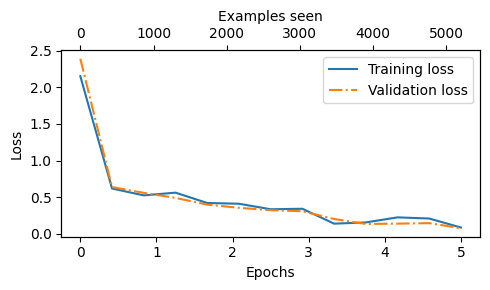

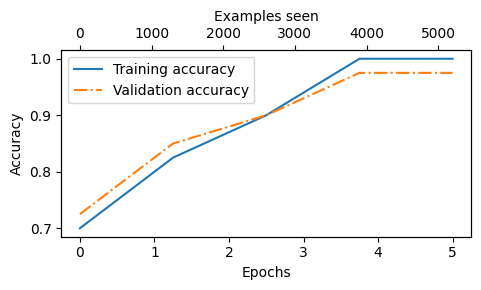

In [8]:
# 2
# -----------------------------------------------------------------------------
# 3. 메인 실행 블록
# -----------------------------------------------------------------------------

test_mode = False
########################################
# 1단계: 데이터셋 다운로드 및 준비
########################################

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "data/sms_spam_collection.zip"
extracted_path = "data/sms_spam_collection"
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

try:
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)
except (requests.exceptions.RequestException, TimeoutError) as e:
    print(f"Primary URL failed: {e}. Trying backup URL...")
    url = "https://f001.backblazeb2.com/file/LLMs-from-scratch/sms%2Bspam%2Bcollection.zip"
    download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)

# 데이터 로드 및 전처리
df = pd.read_csv(data_file_path, sep="\t", header=None, names=["Label", "Text"])
balanced_df = create_balanced_dataset(df) # 50:50 균형 데이터셋 생성
balanced_df["Label"] = balanced_df["Label"].map({"ham": 0, "spam": 1}) # 라벨 인코딩

# Train/Val/Test 분할 및 CSV 저장
train_df, validation_df, test_df = random_split(balanced_df, 0.7, 0.1)
train_df.to_csv("data/train.csv", index=None)
validation_df.to_csv("data/validation.csv", index=None)
test_df.to_csv("data/test.csv", index=None)

########################################
# 2단계: 데이터 로더 생성
########################################
tokenizer = tiktoken.get_encoding("gpt2")

# 학습 데이터셋 생성
train_dataset = SpamDataset(
    csv_file="data/train.csv",
    max_length=None, # 가장 긴 문장에 맞춰 자동 설정
    tokenizer=tokenizer
)

# 검증/테스트 데이터셋은 학습 데이터셋의 max_length를 따름 (일관성 유지)
val_dataset = SpamDataset(
    csv_file="data/validation.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

test_dataset = SpamDataset(
    csv_file="data/test.csv",
    max_length=train_dataset.max_length,
    tokenizer=tokenizer
)

num_workers = 0
batch_size = 8
torch.manual_seed(123)

# DataLoader 생성
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True, # 학습 데이터는 섞음
    num_workers=num_workers,
    drop_last=True,
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

########################################
# 3단계: 사전 학습된 모델 로드 (Pre-trained Model Loading)
########################################

if test_mode:
    # 테스트 모드일 때는 아주 작은 더미 모델 생성
    BASE_CONFIG = {
        "vocab_size": 50257,
        "context_length": 120,
        "drop_rate": 0.0,
        "qkv_bias": False,
        "emb_dim": 12,
        "n_layers": 1,
        "n_heads": 2
    }
    model = GPTModel(BASE_CONFIG)
    model.eval()
    device = "cpu"

else:
    # 실제 GPT-2 Small (124M 파라미터) 모델 설정 및 가중치 로드
    CHOOSE_MODEL = "gpt2-small (124M)"
    
    BASE_CONFIG = {
        "vocab_size": 50257,     
        "context_length": 1024,  
        "drop_rate": 0.0,        
        "qkv_bias": True         
    }

    model_configs = {
        "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
        # 다른 모델 사이즈 설정들...
        "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
        "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
        "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
    }

    BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

    # 데이터셋의 길이가 모델의 컨텍스트 길이를 초과하는지 확인
    assert train_dataset.max_length <= BASE_CONFIG["context_length"], (
        f"Dataset length {train_dataset.max_length} exceeds model's context "
        f"length {BASE_CONFIG['context_length']}. Reinitialize data sets with "
        f"`max_length={BASE_CONFIG['context_length']}`"
    )

    model_name = "gpt2-small-124M.pth"
    model = load_gpt2_model(model_name, BASE_CONFIG)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

########################################
# 4단계: 모델 수정 및 미세 조정 설정 (Fine-tuning Setup)
########################################

# 1. 모든 파라미터를 고정(Freeze)하여 학습되지 않게 설정
# TODO: 파라미터 동결을 위한 값을 채우세요.
# 힌트: 파라미터를 학습에서 제외하려면 requires_grad를 False로 설정합니다.
for param in model.parameters():
    # param.requires_grad = ????
    param.requires_grad = False

torch.manual_seed(123)

# 2. 출력층(Head) 교체: 기존 50257개 단어 예측 -> 2개 클래스(스팸/햄) 예측
# 이 새로운 층은 기본적으로 requires_grad=True 상태임
num_classes = 2
# region [출력층(Head) 교체]
# TODO: 출력층의 클래스 수를 채우세요.
# 힌트: 이진 분류(스팸/햄) 문제이므로 위에서 정의한 num_classes를 사용합니다.
# model.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"], out_features=????)
model.out_head = torch.nn.Linear(in_features=BASE_CONFIG["emb_dim"], out_features=num_classes)
# endregion

model.to(device)

# 3. 추가적으로 마지막 트랜스포머 블록과 정규화 층을 학습 가능하도록 잠금 해제 (Unfreeze)
# -> 이렇게 하면 출력층과 모델의 마지막 부분만 데이터에 맞게 조정됨 (효율적 학습)
# region [마지막 트랜스포머 블록과 정규화 층 잠금 해제]
# TODO: 학습할 마지막 블록 인덱스와 학습 허용 값을 채우세요.
# 힌트: 마지막 트랜스포머 블록만 학습하려면 인덱스 -1과 requires_grad = True를 사용합니다.
# for param in model.trf_blocks[????].parameters():
for param in model.trf_blocks[-1].parameters():
    # param.requires_grad = ????
    param.requires_grad = True

# TODO: 정규화 층 학습 허용 값을 채우세요.
# 힌트: requires_grad를 True로 설정하면 해당 파라미터가 학습 대상이 됩니다.
for param in model.final_norm.parameters():
    # param.requires_grad = ????
    param.requires_grad = True
# endregion

########################################
# 5단계: 모델 미세 조정 (Fine-tuning) 실행
########################################

start_time = time.time()
torch.manual_seed(123)

# 옵티마이저 설정 (학습 가능한 파라미터만 전달됨)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.1)

num_epochs = 5
# 학습 함수 호출
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

########################################
# 6단계: 결과 시각화
########################################

# Loss 그래프 그리기
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))
plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

# Accuracy 그래프 그리기
epochs_tensor = torch.linspace(0, num_epochs, len(train_accs))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_accs))
plot_values(epochs_tensor, examples_seen_tensor, train_accs, val_accs, label="accuracy")

---
## 📌 Chapter 6 정리

```
 pretrained GPT-2  ->  freeze all  ->  new head (768 -> 2)  ->  unfreeze last block + final_norm
                   ->  train on spam data  ->  classify using the LAST token's output
```

**꼭 기억할 4가지**
1. **미세 조정** = 이미 학습된 모델을 내 작업에 맞게 살짝 고치는 것. 적은 데이터와 짧은 시간으로 충분하다.
2. `requires_grad = False` 로 **동결**, `True` 로 **해제**. 보통 뒤쪽 일부만 학습한다.
3. 분류에는 **마지막 토큰**의 출력을 쓴다(문장 전체를 본 유일한 토큰).
4. 데이터는 **균형**을 맞추고, **길이**를 패딩으로 맞추고, **학습/검증/테스트**로 나눈다.